[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pachterlab/OP_2025_2/blob/scope-future/analysis_scripts/Large_Arrays_Rounds.ipynb)

# Large arrays: repeated rounds (`rounds`) and warp subsets (`WARP_SUBSAMPLE`)

Two options of `accumap.reconstruct` for large arrays, continuing `Large_Arrays_Demo.ipynb`:

* **`rounds=k`** runs accumap k times, each round starting from the previous result: the kernel is refitted, and all warp levels
  and both stages run again. Extra passes (`n_passes`) only repeat the second stage. A new round refits the coarse warp from the
  current layout, which can remove a large-scale twist the first round stops short of. The result is the **last** round; it also
  has `round_logliks`, the log-likelihood after each round.
* **`cm.WARP_SUBSAMPLE`** fits the warp on a random fraction of the beads. The default is `None` (all beads); `"auto"` or a
  fraction such as `0.5` is opt-in.

The notebook runs three rounds on a simulated 3 x 7.2 mm array with known bead positions. It shows that each round improves the
layout while the log-likelihood goes down, which is why the last round is returned rather than the one with the highest
log-likelihood. It then runs `rounds=2` with a warp subset. The last section collects the measurements on larger simulations and
real arrays. Runtime on one 8 GB GPU: about 15 min for the start and 10 min for the reconstructions.

In [1]:
# Colab only: clone the repository (scope-future branch) and install accumap; skipped when run locally
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("/content/OP_2025_2"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", "scope-future", "https://github.com/pachterlab/OP_2025_2.git", "/content/OP_2025_2"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "/content/OP_2025_2", "numba"], check=True)
if "google.colab" in sys.modules:
    os.chdir("/content/OP_2025_2/analysis_scripts")

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import accumap
import accumap.count_model as cm
import accumap.multilevel as ml

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (this notebook needs a GPU runtime)")

GPU: NVIDIA GeForce RTX 3070


## 1. A simulated array and its multilevel start

The same array as `Large_Arrays_Demo.ipynb`: a 3 x 7.2 mm shared-bead rectangle (about 37,000 beads) with counts from the
Poisson model fitted to SCOPE's circular array, in large-array mode (`LENGTH_REF_UM`), started from `multilevel_layout`.

In [3]:
W, H = 3000.0, 7200.0
cm.LENGTH_REF_UM = 7000.0           # large-array mode
ml.COARSE_RANDOM_TRIES = 6          # random-init UMAPs at the coarsest level (default 16)
footprint = np.array([[0, 0], [W, 0], [W, H], [0, H]], float) - [W / 2, H / 2]
diameter = float(np.hypot(W, H))
X, C = accumap.simulate_shared_array(W, H, seed=0)
print(f"{C.shape[0]:,} beads, {C.nnz:,} nonzero pairs")

def robust_error(Y, X, keep=0.9):
    """Per-bead error (um) after a similarity alignment refit on the best-placed `keep` fraction of beads."""
    Y, X = np.asarray(Y, float), np.asarray(X, float)
    A, T = accumap.similarity_align(Y, X)
    e = np.linalg.norm(A - T, axis=1)
    for _ in range(3):
        m = e <= np.quantile(e, keep)
        P, Q = Y[m] - Y[m].mean(0), X[m] - X[m].mean(0)
        U, s, Vt = np.linalg.svd(P.T @ Q)
        e = np.linalg.norm((Y - Y[m].mean(0)) @ (U @ Vt) * (s.sum() / np.sum(P ** 2)) - (X - X[m].mean(0)), axis=1)
    return e

t0 = time.time()
E, info = accumap.multilevel_layout(C, footprint=footprint, seed=0, target=1500, verbose=False)
e = robust_error(E, X)
print(f"multilevel start: {time.time() - t0:.0f} s, robust median error {np.median(e):.1f} um")

36,883 beads, 11,767,390 nonzero pairs


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/torch/_inductor/compile_fx.py:167: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


multilevel start: 878 s, robust median error 23.1 um


## 2. Three rounds, one at a time

`rounds=3` is the same as calling `reconstruct` three times, each from the previous receivers. Here the rounds are run one at a
time so each can be scored against the true positions. The log-likelihood is computed the same way as `round_logliks`.

In [4]:
rows, layouts, init = [], [], E
for k in (1, 2, 3):
    t0 = time.time()
    R = accumap.reconstruct(C, init, diameter, shared=True, footprint=footprint, verbose=False)
    Y = np.asarray(R["receivers"], float); e = robust_error(Y, X)
    rows.append({"round": k, "robust median (um)": np.median(e), "p90 (um)": np.percentile(e, 90),
                 "log-likelihood": cm.log_likelihood(C, Y, diameter, shared=True), "time (s)": time.time() - t0})
    layouts.append((Y, e)); init = Y
table = pd.DataFrame(rows).set_index("round")
table.round({"robust median (um)": 2, "p90 (um)": 1, "log-likelihood": 0, "time (s)": 0})

,robust median (um),p90 (um),log-likelihood,time (s)
round,,,,
1,17.20,29.5,-7276748.0,182.0
2,16.10,27.0,-7296246.0,155.0
3,15.95,27.0,-7294460.0,155.0


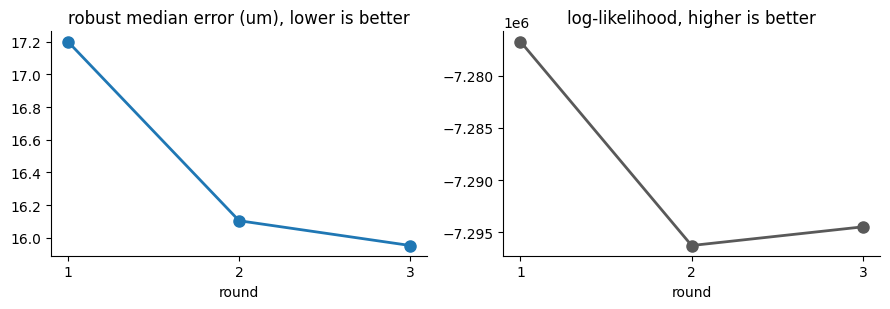

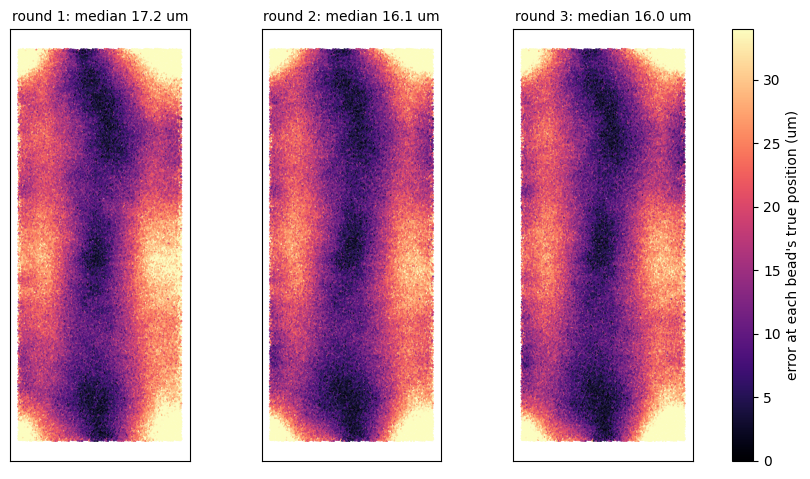

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(table.index, table["robust median (um)"], "o-", color="tab:blue", lw=2, ms=8)
ax[0].set_title("robust median error (um), lower is better")
ax[1].plot(table.index, table["log-likelihood"], "o-", color="0.35", lw=2, ms=8)
ax[1].set_title("log-likelihood, higher is better")
for a in ax:
    a.set_xticks(table.index); a.set_xlabel("round"); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(10, 5.6))
vmax = np.percentile(layouts[0][1], 95)
for a, (k, (Y, e)) in zip(ax, enumerate(layouts, 1)):
    sc = a.scatter(X[:, 0], X[:, 1], c=e, s=0.3, cmap="magma", vmin=0, vmax=vmax)
    a.set_title(f"round {k}: median {np.median(e):.1f} um", fontsize=10); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
fig.colorbar(sc, ax=ax, fraction=0.03, label="error at each bead's true position (um)")
plt.show()

The error is largest at the corners and long edges: a smooth large-scale distortion that each round reduces a little. Each
round lowers the error, but the log-likelihood is highest after round 1. A new round refits the kernel and the background on
a sharper layout, so the log-likelihoods of different rounds come from different fitted models and can't rank layouts that are a
micron apart. Section 4 shows the same on other arrays. accumap therefore returns the last round and does not use the
log-likelihood to choose. `round_logliks` is kept in the result for reference.

## 3. `rounds=2` in one call, with a warp subset

The option form, here with the warp fitted on half of the beads (`cm.WARP_SUBSAMPLE = 0.5`). The result is round 2 and carries
`round_logliks`.

In [6]:
cm.WARP_SUBSAMPLE = 0.5
t0 = time.time()
R2 = accumap.reconstruct(C, E, diameter, shared=True, footprint=footprint, verbose=False, rounds=2)
sec = time.time() - t0
cm.WARP_SUBSAMPLE = None                       # back to the default (all beads)
e = robust_error(R2["receivers"], X)
print(f"rounds = {R2['rounds']}, round_logliks = {np.round(R2['round_logliks'], 0)}")
print(f"warp subset 0.5, rounds=2: robust median {np.median(e):.2f} um, p90 {np.percentile(e, 90):.1f} um, {sec:.0f} s")
print(f"all beads, rounds 1 + 2 above: robust median {table.loc[2, 'robust median (um)']:.2f} um, "
      f"{table.loc[1, 'time (s)'] + table.loc[2, 'time (s)']:.0f} s")

rounds = 2, round_logliks = [-7278700. -7296718.]
warp subset 0.5, rounds=2: robust median 16.26 um, p90 27.4 um, 319 s
all beads, rounds 1 + 2 above: robust median 16.10 um, 337 s


On an array of this size the subset saves little time: the warp is a small part of the run. Differences in error of under
about 1 um between the two are within run-to-run noise. The subset pays off in time only on arrays with around a million beads.
On the SCOPE eye chart it saved 25% of the time but scored lower (next section), so all beads is the default.

## 4. Measurements on larger simulations and real arrays

Measured on bio (two 8 GB GPUs). Real data and the larger simulations are not part of this repository.

**Rounds on simulations with known positions**: robust median error (um), with the round of highest log-likelihood marked *.

| Array | round 1 | round 2 | round 3 |
|---|---|---|---|
| Hu-design distinct-bead 12 mm disc (878k receivers x 207k senders, H4_2's depth) | 20.38 * | 16.48 | 16.23 |
| Hu-design distinct-bead 6 mm disc (220k x 52k) | 12.05 | 11.09 | 10.89 * |
| shared 18 x 18 mm square (553k beads, two GPUs) | 7.40 | 5.39 * | 5.35 |
| shared 3 x 7.2 mm rectangle (this notebook's array, an earlier run) | 16.90 * | 16.20 | 15.47 |
| shared 3 x 1.5 mm, seed 1 | 15.51 * | 14.54 | 15.24 |
| shared 3 x 1.5 mm, seed 2 | 7.89 * | 8.67 | 8.51 |
| calibrated distinct-bead, seed 0 | 15.05 * | 15.09 | 15.04 |
| calibrated distinct-bead, seed 1 | 12.83 * | 12.22 | 12.94 |

The second round helps a lot on the large arrays (19% lower error on the 12 mm Hu-design disc, 27% on the 18 mm square) and is
neutral on small ones (-1.0 to +0.8 um). The log-likelihood picks round 1 on every small array, and on the 12 mm Hu-design disc,
whichever round is most accurate. The Hu-design simulations use H4_2's settings (`LENGTH_REF_UM = 3000`) and a cached
multilevel start (`multilevel_layout_distinct`).

**Rounds on real arrays** (no ground truth):

| Array | Measure | round 1 | round 2 |
|---|---|---|---|
| SCOPE eye chart (1.44M shared beads), four starts | log-likelihood (x1e9) | -3.421 to -3.432 | -3.406 to -3.411 |
| | twist at the right edge | up to 10 deg | removed |
| Hu H4_2 (1.2 cm, 878k receivers x 207k senders) | log-likelihood (x1e7) | -25.43 | -25.62 |

On H4_2 the drop comes mostly from the kernel refitted on the sharper round-1 layout. H4_2 has no ground truth, but on the 12 mm
Hu-design simulation, calibrated to H4_2's depth, round 2 lowers the log-likelihood by a similar 1.0% while lowering the error
from 20.4 to 16.5 um. So the drop on H4_2 most likely does not mean a worse layout.

**Warp subsets**, SCOPE eye chart, two rounds:

| Warp beads | log-likelihood (x1e9) | AUC against the chart image, without the E | time |
|---|---|---|---|
| all (default) | -3.4117 / -3.4084 (two runs) | .873 / .870 | 2.65 h |
| 50% | -3.4133 / -3.4173 | .865 / .844 | 2.0 h |

## Summary

```python
R = accumap.reconstruct(C, start, diameter, shared=True, footprint=footprint, rounds=2)   # returns round 2
R["round_logliks"]                       # log-likelihood after each round, for reference only

import accumap.count_model as cm
cm.WARP_SUBSAMPLE = 0.5                  # opt-in: warp on half the beads (faster on ~1M-bead arrays, slightly less accurate)
```

Use `rounds=2` on large arrays, shared or distinct-bead, where a second round removes large-scale distortions the first leaves;
a third round adds little. On small arrays a second round costs time and changes little.